In [ ]:
!pip install ultralytics opencv-python numpy matplotlib scikit-learn mediapipe open_clip_torch torch Pillow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.9/37.9 MB 43.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 47.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.8 MB/s eta 0:00:00
  Attempting uninstall: absl-py
    Found existing installation: absl-py 1.4.0
    Uninstalling absl-py-1.4.0:
      Successfully uninstalled absl-py-1.4.0


Cargando modelos (los que estén instalados)...
[aviso] MediaPipe Pose no disponible (module 'mediapipe' has no attribute 'solutions'); se sigue solo con YOLO-Pose.


[aviso] MediaPipe SelfieSegmentation no disponible (module 'mediapipe' has no attribute 'solutions'); se sigue solo con YOLO-Seg.
YOLO: OK | MediaPipe: OK | CLIP: OK

Personas detectadas: 3

PERFIL DE PERSONA(S) — image2.jpg

Persona #1
--------------------------------------------------
  Vista: frontal | Confiabilidad: 100%
  ancho_hombros_px: 328.8999938964844
  ancho_hombros_cm: 28.5
  ancho_cintura_px: 397.70001220703125
  ancho_cintura_cm: 34.400001525878906
  ancho_caderas_px: 316.0
  ancho_caderas_cm: 27.399999618530273
  Forma corporal: MANZANA / OVALADO
  Cabello: color=castaño | longitud=medio
  Tono de piel (aprox., por color de píxel): medio
  Prenda superior: vestido (color gris)
  Prenda inferior: legging (color gris)
  Accesorios detectados: ninguno

Persona #2
--------------------------------------------------
  Vista: frontal | Confiabilidad: 100%
  ancho_hombros_px: 338.3999938964844
  ancho_hombros_cm: 33.29999923706055
  ancho_cintura_px: 335.3999938964844
  ancho_c

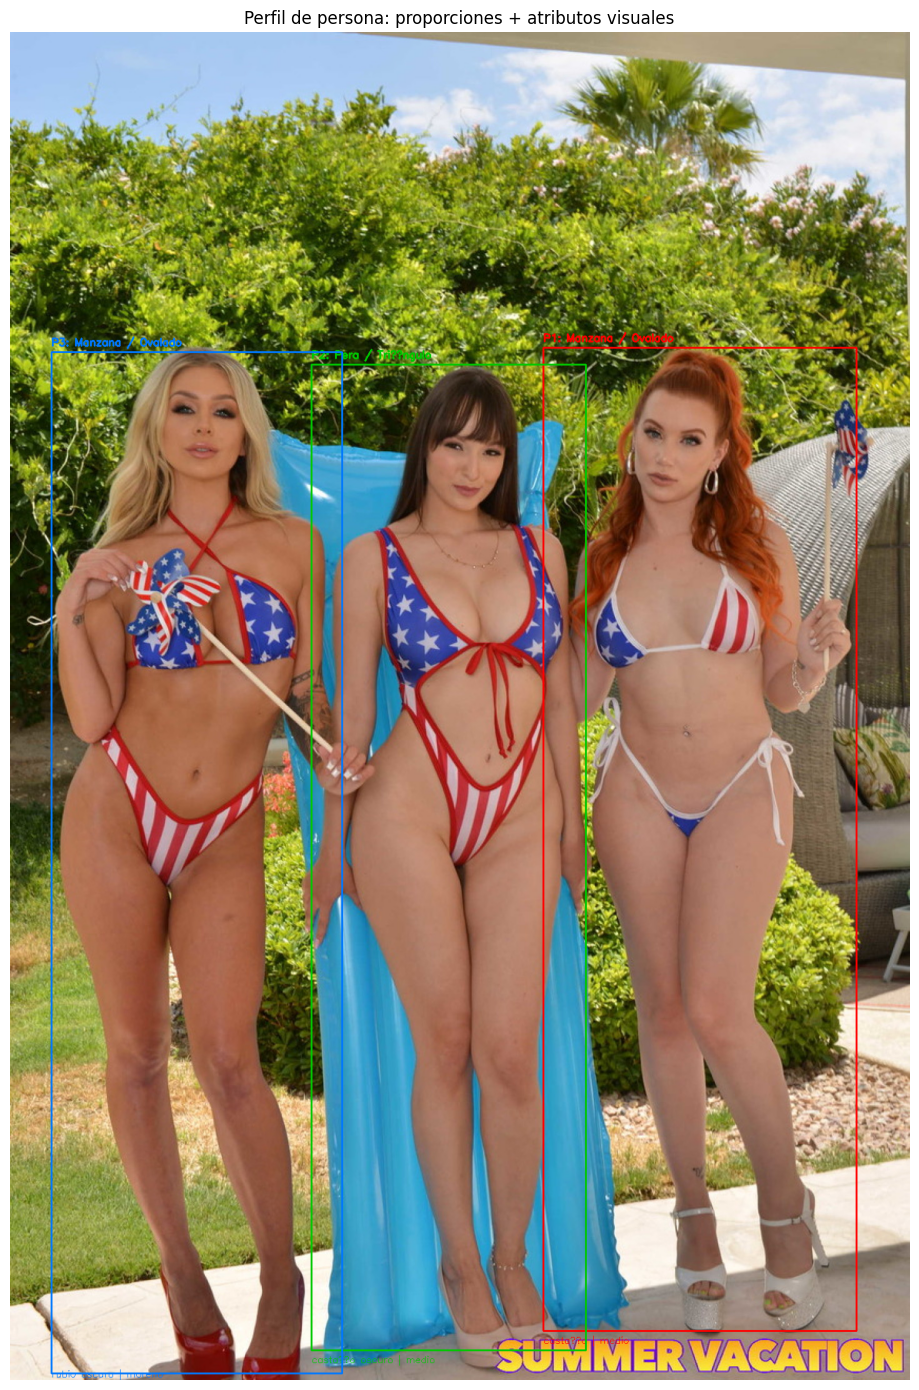

In [ ]:
"""
PersonProfiler — Análisis robusto de proporciones corporales + atributos visuales.

Combina varios modelos (cada uno opcional / con degradación elegante si no
está instalado) para ser tolerante a pose, ángulo, zoom y recorte parcial:

  - Pose:          YOLOv8-Pose (principal) + MediaPipe Pose (relleno / 3D aprox.)
  - Segmentación:  YOLOv8-Seg (principal) + MediaPipe Selfie Segmentation (fallback)
  - Multi-escala:  reintenta la detección con la imagen re-escalada si falla
                    (soluciona personas muy pequeñas -zoom out- o muy grandes -zoom in-)
  - Proporciones:  hombros / cintura / cadera, con corrección de inclinación
                    y de profundidad (usa z de MediaPipe cuando existe)
  - Cabello:       color dominante (KMeans) + longitud aproximada
  - Piel:          tono dominante (KMeans) sobre parches de piel (cara/antebrazo)
  - Ropa:          tipo + color de prenda superior e inferior
                    (CLIP zero-shot si está disponible; si no, heurística de forma+color)
  - Accesorios:    YOLOv8 COCO (mochila, bolso, corbata, paraguas...) + heurística
                    de lentes/gorro sobre la región de la cara

INSTALACIÓN RECOMENDADA (entorno con internet, no este sandbox):
    pip install ultralytics opencv-python numpy matplotlib scikit-learn
    pip install mediapipe                       # pose/segmentación auxiliar
    pip install open_clip_torch torch           # clasificación de ropa zero-shot
    pip install deepface                        # (opcional) edad/género/emoción

    # pesos que se descargan solos la primera vez que se usan:
    yolov8n-pose.pt, yolov8n-seg.pt, yolov8n.pt  (ultralytics, desde GitHub releases)

Cada bloque de imports está protegido con try/except: si una librería no
está instalada, esa capacidad simplemente se desactiva y se informa en el
reporte final ("no disponible"), en vez de romper todo el pipeline.
"""

import warnings
warnings.filterwarnings("ignore")

import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# ---- Dependencias opcionales -------------------------------------------------
try:
    from ultralytics import YOLO
    HAS_YOLO = True
except ImportError:
    HAS_YOLO = False

try:
    import mediapipe as mp
    HAS_MEDIAPIPE = True
except ImportError:
    HAS_MEDIAPIPE = False

try:
    import open_clip
    import torch
    HAS_CLIP = True
except ImportError:
    HAS_CLIP = False


# ============================================================================
# 1. UTILIDADES DE COLOR
# ============================================================================

HAIR_COLOR_TABLE = {
    "negro":        (20, 20, 20),
    "castaño oscuro": (60, 40, 30),
    "castaño":      (100, 65, 45),
    "castaño claro": (140, 100, 70),
    "rubio oscuro": (170, 140, 90),
    "rubio":        (210, 180, 130),
    "rubio claro":  (235, 215, 170),
    "pelirrojo":    (150, 70, 40),
    "gris":         (150, 150, 150),
    "blanco/canoso": (215, 215, 215),
}

SKIN_TONE_TABLE = {
    "muy claro": (245, 220, 200),
    "claro":     (225, 190, 160),
    "medio":     (190, 145, 110),
    "moreno":    (140, 100, 70),
    "oscuro":    (90, 60, 40),
    "muy oscuro": (55, 35, 25),
}

CLOTH_COLOR_NAMES = {
    "negro": (0, 0, 0), "blanco": (255, 255, 255), "gris": (128, 128, 128),
    "rojo": (200, 30, 30), "azul": (30, 60, 200), "azul marino": (20, 30, 80),
    "verde": (40, 140, 60), "amarillo": (230, 210, 40), "naranja": (230, 130, 30),
    "morado": (120, 40, 150), "rosado": (230, 150, 180), "café": (110, 70, 40),
    "beige": (215, 195, 160),
}


def _closest_label(rgb, table):
    rgb = np.array(rgb, dtype=float)
    best, best_d = None, float("inf")
    for name, ref in table.items():
        d = np.linalg.norm(rgb - np.array(ref, dtype=float))
        if d < best_d:
            best, best_d = name, d
    return best


def dominant_color(pixels_rgb, k=3):
    """pixels_rgb: array Nx3. Devuelve el color dominante (ignora outliers)."""
    if pixels_rgb is None or len(pixels_rgb) < k:
        return None
    km = KMeans(n_clusters=min(k, len(pixels_rgb)), n_init=4, random_state=0)
    labels = km.fit_predict(pixels_rgb)
    counts = np.bincount(labels)
    return km.cluster_centers_[np.argmax(counts)]


# ============================================================================
# 2. POSE MULTI-MODELO (YOLO + MediaPipe)
# ============================================================================

class MultiModelPoseEstimator:
    """Ensambla YOLOv8-Pose con MediaPipe Pose para rellenar keypoints faltantes
    y estimar profundidad relativa (mejor detección de perfil / 3-4 / espalda)."""

    COCO_NAMES = ["nose", "l_eye", "r_eye", "l_ear", "r_ear",
                  "l_shoulder", "r_shoulder", "l_elbow", "r_elbow",
                  "l_wrist", "r_wrist", "l_hip", "r_hip",
                  "l_knee", "r_knee", "l_ankle", "r_ankle"]

    def __init__(self, yolo_model="yolov8n-pose.pt"):
        self.yolo = YOLO(yolo_model) if HAS_YOLO else None
        self.mp_pose = None
        if HAS_MEDIAPIPE:
            try:
                self.mp_pose = mp.solutions.pose.Pose(
                    static_image_mode=True, model_complexity=2,
                    min_detection_confidence=0.3)
            except (AttributeError, Exception) as e:
                print(f"[aviso] MediaPipe Pose no disponible ({e}); "
                      f"se sigue solo con YOLO-Pose.")
                self.mp_pose = None

    def _detect_yolo(self, img_bgr, conf):
        if self.yolo is None:
            return []
        people = []
        results = self.yolo(img_bgr, conf=conf, verbose=False)[0]
        if results.keypoints is None:
            return []
        for box, kpts in zip(results.boxes, results.keypoints):
            xyxy = box.xyxy[0].cpu().numpy().astype(int)
            kp = kpts.xy[0].cpu().numpy()
            kp_conf = kpts.conf[0].cpu().numpy() if kpts.conf is not None else np.ones(17)
            people.append({"bbox": xyxy, "keypoints": kp, "kp_conf": kp_conf, "z": None})
        return people

    def _refine_with_mediapipe(self, img_bgr, person):
        """Usa MediaPipe (dentro del bbox de la persona) para rellenar
        keypoints con confianza baja y obtener una z aproximada (profundidad)."""
        if self.mp_pose is None:
            return person
        x1, y1, x2, y2 = person["bbox"]
        x1, y1 = max(0, x1), max(0, y1)
        crop = img_bgr[y1:y2, x1:x2]
        if crop.size == 0:
            return person
        rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
        res = self.mp_pose.process(rgb)
        if not res.pose_landmarks:
            return person

        h, w = crop.shape[:2]
        lm = res.pose_landmarks.landmark
        # Mapeo aproximado MediaPipe(33) -> COCO(17)
        mp_map = {0: 0, 2: 1, 5: 2, 7: 3, 8: 4, 11: 5, 12: 6, 13: 7, 14: 8,
                  15: 9, 16: 10, 23: 11, 24: 12, 25: 13, 26: 14, 27: 15, 28: 16}

        z_vals = np.zeros(17)
        for coco_idx, mp_idx in mp_map.items():
            p = lm[mp_idx]
            visible = p.visibility if hasattr(p, "visibility") else 1.0
            z_vals[coco_idx] = p.z
            if person["kp_conf"][coco_idx] < 0.3 and visible > 0.4:
                person["keypoints"][coco_idx] = [x1 + p.x * w, y1 + p.y * h]
                person["kp_conf"][coco_idx] = visible
        person["z"] = z_vals
        return person

    def detect(self, img_bgr, conf=0.30):
        """Detección con reintento multi-escala: si YOLO no encuentra a nadie
        (persona muy pequeña o muy grande / recortada), se reescala la imagen."""
        people = self._detect_yolo(img_bgr, conf)

        if not people:
            for scale in (1.5, 2.0, 0.6):
                h, w = img_bgr.shape[:2]
                resized = cv2.resize(img_bgr, (int(w * scale), int(h * scale)))
                cand = self._detect_yolo(resized, conf * 0.85)
                if cand:
                    for p in cand:
                        p["bbox"] = (p["bbox"] / scale).astype(int)
                        p["keypoints"] = p["keypoints"] / scale
                    people = cand
                    break

        if HAS_MEDIAPIPE:
            people = [self._refine_with_mediapipe(img_bgr, p) for p in people]

        return people


# ============================================================================
# 3. SEGMENTACIÓN MULTI-MODELO (YOLO-Seg + MediaPipe Selfie Segmentation)
# ============================================================================

class MultiModelSegmenter:
    def __init__(self, yolo_model="yolov8n-seg.pt"):
        self.yolo = YOLO(yolo_model) if HAS_YOLO else None
        self.mp_seg = None
        if HAS_MEDIAPIPE:
            try:
                self.mp_seg = mp.solutions.selfie_segmentation.SelfieSegmentation(model_selection=1)
            except (AttributeError, Exception) as e:
                print(f"[aviso] MediaPipe SelfieSegmentation no disponible ({e}); "
                      f"se sigue solo con YOLO-Seg.")
                self.mp_seg = None

    def _yolo_masks(self, img_bgr, conf):
        if self.yolo is None:
            return []
        h, w = img_bgr.shape[:2]
        results = self.yolo(img_bgr, conf=conf, classes=[0], verbose=False)[0]
        masks = []
        if results.masks is None:
            return []
        for mask_data, box in zip(results.masks.data, results.boxes):
            m = cv2.resize(mask_data.cpu().numpy(), (w, h))
            masks.append({"mask": (m > 0.5).astype(np.uint8),
                          "bbox": box.xyxy[0].cpu().numpy().astype(int)})
        return masks

    def _mediapipe_mask(self, img_bgr, bbox):
        """Fallback de segmentación por persona, útil si YOLO-seg falla
        (fondo complejo, pose extrema, recorte parcial)."""
        if self.mp_seg is None:
            return None
        x1, y1, x2, y2 = bbox
        h, w = img_bgr.shape[:2]
        x1, y1, x2, y2 = max(0, x1), max(0, y1), min(w, x2), min(h, y2)
        crop = img_bgr[y1:y2, x1:x2]
        if crop.size == 0:
            return None
        rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
        res = self.mp_seg.process(rgb)
        if res.segmentation_mask is None:
            return None
        full = np.zeros((h, w), dtype=np.uint8)
        full[y1:y2, x1:x2] = (res.segmentation_mask > 0.5).astype(np.uint8)
        return {"mask": full, "bbox": np.array([x1, y1, x2, y2])}

    def detect(self, img_bgr, people, conf=0.30):
        masks = self._yolo_masks(img_bgr, conf)
        matched = []
        for person in people:
            best = self._match(person, masks)
            if best is None:
                best = self._mediapipe_mask(img_bgr, person["bbox"])
            matched.append(best)
        return matched

    @staticmethod
    def _match(person, masks):
        if not masks:
            return None
        kp = person["keypoints"]
        valid_pts = kp[np.any(kp != 0, axis=1)]
        if len(valid_pts) == 0:
            return None
        center = valid_pts.mean(axis=0)
        best, best_d = None, float("inf")
        for m in masks:
            mx1, my1, mx2, my2 = m["bbox"]
            mc = np.array([(mx1 + mx2) / 2, (my1 + my2) / 2])
            d = np.linalg.norm(center - mc)
            if d < best_d:
                best, best_d = m, d
        return best


# ============================================================================
# 4. ORIENTACIÓN / CONFIABILIDAD (2D + z de MediaPipe si existe)
# ============================================================================

class OrientationEstimator:
    L_SH, R_SH, L_HIP, R_HIP = 5, 6, 11, 12
    L_EAR, R_EAR, L_EYE, R_EYE, NOSE = 3, 4, 1, 2, 0

    @classmethod
    def estimate(cls, person):
        kp, conf = person["keypoints"], person["kp_conf"]
        z = person.get("z")

        def valid(i, th=0.3):
            return conf[i] > th and not (kp[i][0] == 0 and kp[i][1] == 0)

        info = {"vista": "indeterminada", "confiabilidad": 0.0, "razones": [], "_tilt_deg": None}
        both_sh = valid(cls.L_SH) and valid(cls.R_SH)
        both_hip = valid(cls.L_HIP) and valid(cls.R_HIP)

        if not both_sh:
            info.update(vista="perfil o muy angulada", confiabilidad=0.15,
                        razones=["Solo un hombro visible → probable perfil"])
            return info

        score = 1.0
        shoulder_w = np.linalg.norm(kp[cls.L_SH] - kp[cls.R_SH])

        # Señal extra: si tenemos z de MediaPipe, un delta z grande entre
        # hombros = persona rotada respecto a la cámara (más fiable que 2D solo)
        if z is not None and shoulder_w > 0:
            dz = abs(z[cls.L_SH] - z[cls.R_SH])
            if dz > 0.15:
                info["razones"].append(f"Diferencia de profundidad entre hombros ({dz:.2f}) → vista rotada")
                score *= max(0.3, 1 - dz)

        if valid(cls.NOSE):
            mid_x = (kp[cls.L_SH][0] + kp[cls.R_SH][0]) / 2
            centering = abs(kp[cls.NOSE][0] - mid_x) / shoulder_w if shoulder_w else None
            if centering is not None:
                if centering > 0.35:
                    info["vista"] = "3/4 (girada)"
                    score *= 0.6
                else:
                    info["vista"] = "frontal"

        if info["vista"] == "indeterminada":
            info["vista"] = "frontal (asumida)"

        if both_sh and both_hip:
            mid_sh = (kp[cls.L_SH] + kp[cls.R_SH]) / 2
            mid_hip = (kp[cls.L_HIP] + kp[cls.R_HIP]) / 2
            dx, dy = mid_hip[0] - mid_sh[0], mid_hip[1] - mid_sh[1]
            tilt = abs(np.degrees(np.arctan2(dx, dy)))
            info["_tilt_deg"] = tilt
            if tilt > 15:
                info["razones"].append(f"Torso inclinado {tilt:.1f}°")
                score *= max(0.4, 1 - (tilt - 15) / 60)

        if not both_hip:
            info["razones"].append("Caderas no visibles → sin cintura/cadera fiable")
            score *= 0.3

        key_confs = [conf[i] for i in [cls.L_SH, cls.R_SH, cls.L_HIP, cls.R_HIP] if conf[i] > 0]
        if key_confs:
            score *= np.mean(key_confs)

        info["confiabilidad"] = round(float(np.clip(score, 0, 1)), 2)
        return info


# ============================================================================
# 5. PROPORCIONES CORPORALES (hombros / cintura / cadera)
# ============================================================================

class BodyProportions:
    L_SH, R_SH, L_HIP, R_HIP = 5, 6, 11, 12
    L_EAR, R_EAR, L_EYE, R_EYE = 3, 4, 1, 2

    @staticmethod
    def _width_at_y(mask, y, x_range, tilt_deg=None, n_rows=3):
        """Promedia varias filas alrededor de y para reducir ruido de la máscara."""
        h, w = mask.shape
        widths = []
        for dy in range(-n_rows, n_rows + 1):
            yy = int(np.clip(y + dy, 0, h - 1))
            row = mask[yy, :].copy()
            x0, x1 = x_range
            row[:max(0, x0)] = 0
            row[min(w, x1):] = 0
            xs = np.where(row > 0)[0]
            if len(xs):
                widths.append(xs.max() - xs.min())
        if not widths:
            return None
        raw = float(np.median(widths))
        if tilt_deg and tilt_deg > 3:
            corr = np.cos(np.radians(min(tilt_deg, 45)))
            return round(raw * corr, 1) if corr > 0.3 else raw
        return round(raw, 1)

    @classmethod
    def measure(cls, person, mask_entry, orientation):
        kp, conf = person["keypoints"], person["kp_conf"]
        mask = mask_entry["mask"]
        mx1, my1, mx2, my2 = mask_entry["bbox"]
        tilt = orientation.get("_tilt_deg")

        def valid(i):
            return conf[i] > 0.3 and not (kp[i][0] == 0 and kp[i][1] == 0)

        out = {}
        if valid(cls.L_SH) and valid(cls.R_SH):
            y = int((kp[cls.L_SH][1] + kp[cls.R_SH][1]) / 2)
            out["ancho_hombros_px"] = cls._width_at_y(mask, y, (mx1, mx2), tilt)
            out["_y_shoulder"] = y
        if valid(cls.L_HIP) and valid(cls.R_HIP):
            y = int((kp[cls.L_HIP][1] + kp[cls.R_HIP][1]) / 2)
            out["ancho_caderas_px"] = cls._width_at_y(mask, y, (mx1, mx2), tilt)
            out["_y_hip"] = y
        if "_y_shoulder" in out and "_y_hip" in out:
            y = int(out["_y_shoulder"] + (out["_y_hip"] - out["_y_shoulder"]) * 0.58)
            out["ancho_cintura_px"] = cls._width_at_y(mask, y, (mx1, mx2), tilt)
            out["_y_waist"] = y
        return out

    @staticmethod
    def get_px_to_cm_factor(person, ref_pixel_width=None, ref_cm_width=None):
        if ref_pixel_width and ref_cm_width:
            return ref_cm_width / ref_pixel_width
        kp, conf = person["keypoints"], person["kp_conf"]
        L_EAR, R_EAR, L_EYE, R_EYE = 3, 4, 1, 2

        def valid(i):
            return conf[i] > 0.3 and not (kp[i][0] == 0 and kp[i][1] == 0)

        if valid(L_EAR) and valid(R_EAR):
            face_px = np.linalg.norm(kp[L_EAR] - kp[R_EAR])
        elif valid(L_EYE) and valid(R_EYE):
            face_px = np.linalg.norm(kp[L_EYE] - kp[R_EYE]) * 2.2
        else:
            return None
        AVG_FACE_WIDTH_CM = 14.0
        return AVG_FACE_WIDTH_CM / face_px if face_px > 0 else None

    @staticmethod
    def classify_shape(m, confiabilidad):
        if confiabilidad < 0.4:
            return {"tipo": "No confiable", "razon": "Ángulo/pose no permite medir bien la silueta."}
        s, w, h = m.get("ancho_hombros_px"), m.get("ancho_cintura_px"), m.get("ancho_caderas_px")
        if not (s and w and h):
            return {"tipo": "Indeterminado", "razon": "Faltan medidas clave."}
        sh_diff = abs(s - h) / max(s, h) * 100
        whr, wsr = w / h, w / s
        detalles = [f"Hombro:{s}px Cintura:{w}px Cadera:{h}px",
                    f"cintura/cadera={whr:.2f} cintura/hombro={wsr:.2f}"]
        if whr > 0.90 and wsr > 0.90:
            tipo = "Manzana / Ovalado"
        elif sh_diff < 8 and whr < 0.78:
            tipo = "Reloj de arena"
        elif h > s and (h - s) / s * 100 > 8:
            tipo = "Pera / Triángulo"
        elif s > h and (s - h) / h * 100 > 8:
            tipo = "Triángulo invertido"
        else:
            tipo = "Rectángulo"
        return {"tipo": tipo, "detalles": detalles, "waist_hip_ratio": round(whr, 2)}


# ============================================================================
# 6. CABELLO — color y longitud aproximada
# ============================================================================

class HairAnalyzer:
    L_EAR, R_EAR, NOSE, L_SH, R_SH, L_HIP = 3, 4, 0, 5, 6, 11

    @classmethod
    def analyze(cls, img_rgb, person, mask_entry):
        kp, conf = person["keypoints"], person["kp_conf"]
        x1, y1, x2, y2 = person["bbox"]

        def valid(i):
            return conf[i] > 0.25 and not (kp[i][0] == 0 and kp[i][1] == 0)

        if not valid(cls.NOSE):
            return {"color": "no detectado", "longitud": "no detectado"}

        # Región de cabello: banda sobre la cabeza + laterales, dentro del bbox
        head_top = y1
        eye_y = int(kp[cls.NOSE][1])
        band_bottom = eye_y
        hair_region = img_rgb[max(0, head_top):max(1, band_bottom), x1:x2]

        if mask_entry is not None:
            m = mask_entry["mask"][max(0, head_top):max(1, band_bottom), x1:x2]
            if m.shape[:2] == hair_region.shape[:2]:
                hair_region = hair_region[m.astype(bool)] if m.any() else hair_region.reshape(-1, 3)
            else:
                hair_region = hair_region.reshape(-1, 3)
        else:
            hair_region = hair_region.reshape(-1, 3)

        pixels = hair_region.reshape(-1, 3) if hair_region.ndim == 3 else hair_region
        # descarta píxeles muy claros (posible fondo) y muy oscuros (sombra dura)
        if len(pixels) > 20:
            lum = pixels.mean(axis=1)
            pixels = pixels[(lum > 10) & (lum < 250)]

        color_rgb = dominant_color(pixels, k=3)
        color_label = _closest_label(color_rgb, HAIR_COLOR_TABLE) if color_rgb is not None else "no detectado"

        # Longitud aproximada: ¿la máscara de persona se extiende angosta
        # (pelo) por debajo de la línea de hombros u orejas?
        longitud = "corto"
        if mask_entry is not None and valid(cls.L_SH) and valid(cls.R_SH):
            shoulder_y = int((kp[cls.L_SH][1] + kp[cls.R_SH][1]) / 2)
            ear_y = int(kp[cls.L_EAR][1]) if valid(cls.L_EAR) else eye_y
            mask = mask_entry["mask"]
            # ancho de la "cabeza+cuello" justo antes del hombro vs en la oreja
            def width_at(y):
                yy = int(np.clip(y, 0, mask.shape[0] - 1))
                row = mask[yy, x1:x2]
                xs = np.where(row > 0)[0]
                return (xs.max() - xs.min()) if len(xs) else 0
            w_ear = width_at(ear_y)
            w_neck = width_at(int((ear_y + shoulder_y) / 2))
            if w_neck > w_ear * 1.4:
                longitud = "largo (cubre hombros/cuello)"
            elif w_neck > w_ear * 1.1:
                longitud = "medio"

        return {"color": color_label, "longitud": longitud}


# ============================================================================
# 7. PIEL — tono dominante
# ============================================================================

class SkinToneAnalyzer:
    NOSE, L_EYE, R_EYE = 0, 1, 2
    L_ELBOW, R_ELBOW, L_WRIST, R_WRIST = 7, 8, 9, 10

    @classmethod
    def analyze(cls, img_rgb, person):
        kp, conf = person["keypoints"], person["kp_conf"]

        def valid(i):
            return conf[i] > 0.25 and not (kp[i][0] == 0 and kp[i][1] == 0)

        patches = []
        # parche de mejilla (bajo el ojo, entre ojo y nariz-boca aprox.)
        if valid(cls.NOSE) and valid(cls.L_EYE):
            cx, cy = kp[cls.L_EYE]
            r = 8
            patches.append(cls._sample(img_rgb, cx, cy + 15, r))
        if valid(cls.NOSE) and valid(cls.R_EYE):
            cx, cy = kp[cls.R_EYE]
            r = 8
            patches.append(cls._sample(img_rgb, cx, cy + 15, r))
        # antebrazo, si es visible (brazos descubiertos)
        for a, b in [(cls.L_ELBOW, cls.L_WRIST), (cls.R_ELBOW, cls.R_WRIST)]:
            if valid(a) and valid(b):
                mx, my = (kp[a] + kp[b]) / 2
                patches.append(cls._sample(img_rgb, mx, my, 10))

        pixels = np.vstack([p for p in patches if p is not None]) if patches else None
        if pixels is None or len(pixels) < 5:
            return {"tono": "no detectado"}

        color_rgb = dominant_color(pixels, k=2)
        tono = _closest_label(color_rgb, SKIN_TONE_TABLE) if color_rgb is not None else "no detectado"
        return {"tono": tono}

    @staticmethod
    def _sample(img_rgb, cx, cy, r):
        h, w = img_rgb.shape[:2]
        cx, cy = int(cx), int(cy)
        x0, x1 = max(0, cx - r), min(w, cx + r)
        y0, y1 = max(0, cy - r), min(h, cy + r)
        if x1 <= x0 or y1 <= y0:
            return None
        return img_rgb[y0:y1, x0:x1].reshape(-1, 3)


# ============================================================================
# 8. ROPA — tipo y color (CLIP zero-shot si está disponible; si no, heurística)
# ============================================================================

class ClothingAnalyzer:
    L_SH, R_SH, L_HIP, R_HIP, L_ANKLE, R_ANKLE = 5, 6, 11, 12, 15, 16
    UPPER_LABELS = ["camiseta", "camisa", "blusa", "vestido", "chaqueta",
                    "sudadera con capucha", "abrigo", "suéter", "top deportivo"]
    LOWER_LABELS = ["pantalón largo", "jean", "short", "falda", "vestido",
                    "legging", "pantalón deportivo"]

    def __init__(self):
        self.clip_model = self.clip_preprocess = self.clip_tokenizer = None
        if HAS_CLIP:
            try:
                self.clip_model, _, self.clip_preprocess = open_clip.create_model_and_transforms(
                    "ViT-B-32", pretrained="openai")
                self.clip_tokenizer = open_clip.get_tokenizer("ViT-B-32")
                self.clip_model.eval()
            except Exception:
                self.clip_model = None

    def _clip_classify(self, crop_rgb, labels):
        if self.clip_model is None or crop_rgb.size == 0:
            return None
        from PIL import Image
        img = self.clip_preprocess(Image.fromarray(crop_rgb)).unsqueeze(0)
        text = self.clip_tokenizer([f"una foto de una prenda tipo {l}" for l in labels])
        with torch.no_grad():
            img_f = self.clip_model.encode_image(img)
            txt_f = self.clip_model.encode_text(text)
            img_f /= img_f.norm(dim=-1, keepdim=True)
            txt_f /= txt_f.norm(dim=-1, keepdim=True)
            sims = (img_f @ txt_f.T).squeeze(0)
        return labels[int(sims.argmax())]

    def analyze(self, img_rgb, person, mask_entry):
        kp, conf = person["keypoints"], person["kp_conf"]
        x1, y1, x2, y2 = person["bbox"]

        def valid(i):
            return conf[i] > 0.25 and not (kp[i][0] == 0 and kp[i][1] == 0)

        result = {"prenda_superior": {}, "prenda_inferior": {}}

        if valid(self.L_SH) and valid(self.R_SH) and valid(self.L_HIP) and valid(self.R_HIP):
            y_top = int((kp[self.L_SH][1] + kp[self.R_SH][1]) / 2)
            y_bot = int((kp[self.L_HIP][1] + kp[self.R_HIP][1]) / 2)
            upper_crop = img_rgb[max(0, y_top):max(1, y_bot), x1:x2]
            result["prenda_superior"] = self._describe(upper_crop, mask_entry, y_top, y_bot,
                                                        x1, x2, self.UPPER_LABELS)

            y_top2 = y_bot
            if valid(self.L_ANKLE) or valid(self.R_ANKLE):
                ankles = [kp[i][1] for i in (self.L_ANKLE, self.R_ANKLE) if valid(i)]
                y_bot2 = int(np.mean(ankles))
            else:
                y_bot2 = y2
            lower_crop = img_rgb[max(0, y_top2):max(1, y_bot2), x1:x2]
            result["prenda_inferior"] = self._describe(lower_crop, mask_entry, y_top2, y_bot2,
                                                        x1, x2, self.LOWER_LABELS)
        return result

    def _describe(self, crop_rgb, mask_entry, y0, y1, x0, x1, labels):
        if crop_rgb.size == 0:
            return {"tipo": "no detectado", "color": "no detectado"}

        pixels = crop_rgb.reshape(-1, 3)
        if mask_entry is not None:
            m = mask_entry["mask"][max(0, y0):max(1, y1), x0:x1]
            if m.shape == crop_rgb.shape[:2] and m.any():
                pixels = crop_rgb[m.astype(bool)]

        color_rgb = dominant_color(pixels, k=3)
        color_label = _closest_label(color_rgb, CLOTH_COLOR_NAMES) if color_rgb is not None else "no detectado"

        tipo = self._clip_classify(crop_rgb, labels)
        if tipo is None:
            # heurística de respaldo sin CLIP: forma de la máscara
            tipo = self._shape_heuristic(mask_entry, y0, y1, x0, x1, labels)

        return {"tipo": tipo, "color": color_label}

    @staticmethod
    def _shape_heuristic(mask_entry, y0, y1, x0, x1, labels):
        """Sin CLIP: usa si la región se separa en dos piernas (pantalón/short)
        o queda unida (falda/vestido) y el largo relativo para short vs largo."""
        if mask_entry is None:
            return "prenda (tipo no determinado, instala CLIP para detalle)"
        mask = mask_entry["mask"]
        h = mask.shape[0]
        y0, y1 = max(0, y0), min(h, y1)
        if y1 <= y0:
            return "prenda (tipo no determinado)"
        mid_row = mask[int((y0 + y1) / 2), x0:x1]
        xs = np.where(mid_row > 0)[0]
        if len(xs) == 0:
            return "prenda (tipo no determinado)"
        gap = np.diff(xs)
        splits_into_legs = np.any(gap > (xs.max() - xs.min()) * 0.15)
        if "falda" in labels or "vestido" in labels:  # se está describiendo la parte inferior
            return "pantalón/short (piernas separadas)" if splits_into_legs else "falda/vestido (una sola pieza)"
        return "prenda superior"


# ============================================================================
# 9. ACCESORIOS — YOLO COCO + heurística de lentes/gorro
# ============================================================================

class AccessoryDetector:
    COCO_ACCESSORIES = {24: "mochila", 26: "bolso/cartera", 27: "corbata", 28: "maleta", 25: "paraguas"}

    def __init__(self, yolo_model="yolov8n.pt"):
        self.yolo = YOLO(yolo_model) if HAS_YOLO else None

    def detect(self, img_bgr, person_bbox, conf=0.3):
        found = []
        if self.yolo is not None:
            results = self.yolo(img_bgr, conf=conf, verbose=False)[0]
            px1, py1, px2, py2 = person_bbox
            for box in results.boxes:
                cls_id = int(box.cls[0])
                if cls_id in self.COCO_ACCESSORIES:
                    bx1, by1, bx2, by2 = box.xyxy[0].cpu().numpy()
                    # ¿el accesorio se solapa con la persona?
                    if bx1 < px2 and bx2 > px1 and by1 < py2 and by2 > py1:
                        found.append(self.COCO_ACCESSORIES[cls_id])
        return found


# ============================================================================
# 10. ORQUESTADOR PRINCIPAL
# ============================================================================

class PersonProfiler:
    def __init__(self, img_path, ref_pixel_width=None, ref_cm_width=None):
        self.img_path = img_path
        self.img_bgr = cv2.imread(img_path)
        if self.img_bgr is None:
            raise FileNotFoundError(f"No se pudo leer {img_path}")
        self.img_rgb = cv2.cvtColor(self.img_bgr, cv2.COLOR_BGR2RGB)
        self.ref_pixel_width = ref_pixel_width
        self.ref_cm_width = ref_cm_width

        print("Cargando modelos (los que estén instalados)...")
        self.pose_est = MultiModelPoseEstimator()
        self.seg_est = MultiModelSegmenter()
        self.hair = HairAnalyzer()
        self.skin = SkinToneAnalyzer()
        self.clothing = ClothingAnalyzer()
        self.accessories = AccessoryDetector()
        print(f"YOLO: {'OK' if HAS_YOLO else 'no instalado'} | "
              f"MediaPipe: {'OK' if HAS_MEDIAPIPE else 'no instalado'} | "
              f"CLIP: {'OK' if HAS_CLIP else 'no instalado'}\n")

    def analyze(self):
        people = self.pose_est.detect(self.img_bgr)
        masks = self.seg_est.detect(self.img_bgr, people)
        print(f"Personas detectadas: {len(people)}")

        self.results = []
        for i, (person, mask_entry) in enumerate(zip(people, masks)):
            orientation = OrientationEstimator.estimate(person)

            entry = {"idx": i, "bbox": person["bbox"], "orientation": orientation}

            if mask_entry is None:
                entry["error"] = "No se pudo obtener silueta (ni YOLO-seg ni MediaPipe)"
                self.results.append(entry)
                continue

            m = BodyProportions.measure(person, mask_entry, orientation)
            px_to_cm = BodyProportions.get_px_to_cm_factor(person, self.ref_pixel_width, self.ref_cm_width)
            if px_to_cm:
                for key in ["ancho_hombros_px", "ancho_cintura_px", "ancho_caderas_px"]:
                    if m.get(key):
                        m[key.replace("_px", "_cm")] = round(m[key] * px_to_cm, 1)
            entry["measurements"] = m
            entry["shape"] = BodyProportions.classify_shape(m, orientation["confiabilidad"])
            entry["mask"] = mask_entry["mask"]

            entry["cabello"] = self.hair.analyze(self.img_rgb, person, mask_entry)
            entry["piel"] = self.skin.analyze(self.img_rgb, person)
            entry["ropa"] = self.clothing.analyze(self.img_rgb, person, mask_entry)
            entry["accesorios"] = self.accessories.detect(self.img_bgr, person["bbox"])

            self.results.append(entry)
        return self.results

    # ---------------------------------------------------------------- report
    def print_report(self):
        print("\n" + "=" * 72)
        print(f"PERFIL DE PERSONA(S) — {self.img_path}")
        print("=" * 72)
        for r in self.results:
            print(f"\nPersona #{r['idx']+1}")
            print("-" * 50)
            if "error" in r:
                print(f"  {r['error']}")
                continue

            o = r["orientation"]
            print(f"  Vista: {o['vista']} | Confiabilidad: {o['confiabilidad']*100:.0f}%")
            for razon in o["razones"]:
                print(f"    - {razon}")

            if o["confiabilidad"] >= 0.4:
                m = r["measurements"]
                for key in ["ancho_hombros_px", "ancho_hombros_cm", "ancho_cintura_px",
                            "ancho_cintura_cm", "ancho_caderas_px", "ancho_caderas_cm"]:
                    if key in m:
                        print(f"  {key}: {m[key]}")
                print(f"  Forma corporal: {r['shape']['tipo'].upper()}")
            else:
                print("  ⚠ Proporciones no confiables con este ángulo/pose.")

            print(f"  Cabello: color={r['cabello'].get('color')} | longitud={r['cabello'].get('longitud')}")
            print(f"  Tono de piel (aprox., por color de píxel): {r['piel'].get('tono')}")
            ps, pi = r["ropa"]["prenda_superior"], r["ropa"]["prenda_inferior"]
            print(f"  Prenda superior: {ps.get('tipo')} (color {ps.get('color')})")
            print(f"  Prenda inferior: {pi.get('tipo')} (color {pi.get('color')})")
            print(f"  Accesorios detectados: {', '.join(r['accesorios']) if r['accesorios'] else 'ninguno'}")

    def plot(self):
        img_draw = self.img_rgb.copy()
        colors = [(255, 0, 0), (0, 200, 0), (0, 120, 255), (255, 150, 0), (200, 0, 255)]
        for r in self.results:
            c = colors[r["idx"] % len(colors)]
            x1, y1, x2, y2 = r["bbox"]
            cv2.rectangle(img_draw, (x1, y1), (x2, y2), c, 2)
            tipo = r["shape"]["tipo"] if "error" not in r else "sin silueta"
            label = f"P{r['idx']+1}: {tipo}"
            cv2.putText(img_draw, label, (x1, max(y1 - 10, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.55, c, 2)
            if "error" not in r:
                sub = f"{r['cabello'].get('color')} | {r['piel'].get('tono')}"
                cv2.putText(img_draw, sub, (x1, min(y2 + 20, img_draw.shape[0] - 5)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, c, 1)

        plt.figure(figsize=(12, 14))
        plt.imshow(img_draw)
        plt.axis('off')
        plt.title("Perfil de persona: proporciones + atributos visuales")
        plt.tight_layout()
        plt.show()

    def run(self):
        self.analyze()
        self.print_report()
        self.plot()


# ============ USO ============
if __name__ == "__main__":
    profiler = PersonProfiler("image2.jpg")
    profiler.run()


In [ ]:
from google.colab import files
uploaded = files.upload()  # sube tu imagen (ej. image1.jpg)
img_name = list(uploaded.keys())[0]
profiler = PersonProfiler(img_name)
profiler.run()